# 01 · Data export and preprocessing

Builds a **global** training dataset for Sentinel-1-only LULC segmentation.

**Data sources (Google Earth Engine):** input `COPERNICUS/S1_GRD` (Sentinel-1 IW, VV + VH, 10 m); labels `GOOGLE/DYNAMICWORLD/V1` (Sentinel-2-based near-real-time land cover, used only as training and test labels).

| Step | What happens |
|---|---|
| 1 | 40 study areas (20.48 × 20.48 km) on six continents, split by region into train / val / test |
| 2 | Sentinel-1 coverage per orbit pass → one pass per area |
| 3 | Pilot: export and inspect one area for one month |
| 4 | Export all area-months from Google Earth Engine (S1 composite + Dynamic World label) |
| 5 | Integrity check of the downloaded tiles |
| 6 | Cut tiles into 256 × 256 patches, class distribution, normalisation statistics |

**Time split:** training and validation use **2023–2024**, testing uses **2025–2026**.

| Split | Study areas | Period | Purpose |
|---|---|---|---|
| `train` | 27 train areas (26 with data, see section 4) | 2023–24 | fitting |
| `val` | 4 val areas | 2023–24 | model selection, early stopping |
| `test` | 9 test areas | 2025–26 | **main test**: unseen places, future dates |
| `test_temporal` | the train areas | 2025–26 | robustness over time only (places are known) |

**Run on the lab server.** Section 4 can also run in the background with
`nohup python scripts/run_export.py > export.log 2>&1 &`; then the export cell here only verifies the files.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from concurrent.futures import ThreadPoolExecutor, as_completed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from tqdm.auto import tqdm
import ee
import folium
from pyproj import Transformer

from src import config as C, gee_data as G, patching as P

G.init()
CMAP = ListedColormap(C.CLASS_COLORS)
SPLIT_COLORS = {"train": "#2563eb", "val": "#f59e0b", "test": "#dc2626"}
print("GEE project:", C.GEE_PROJECT, "| raw:", C.RAW_DIR, "| patches:", C.PATCH_DIR)

GEE project: lulc-sentinel-1 | raw: /home/jovyan/vault/Deep Learning project/lulc-s1/data/raw_global | patches: /home/jovyan/vault/Deep Learning project/lulc-s1/data/patches_global


## 1. Classes and study areas

Eight classes, identical to the **Esri 10 m Annual LULC** map (without its *clouds* class), which is the
independent reference for the prototype case study. Labels come from **Dynamic World** (Sentinel-2 based,
9 classes); grass and shrub/scrub are merged into *rangeland* because their C-band backscatter is too similar.

In [2]:
pd.DataFrame({"class": C.CLASSES,
              "from Dynamic World": [", ".join(d for d, c in zip(C.DW_BANDS, C.DW_TO_CLASS) if c == i)
                                     for i in range(len(C.CLASSES))]}).rename_axis("index")

,class,from Dynamic World
index,,
0,water,water
1,trees,trees
2,flooded_vegetation,flooded_vegetation
3,crops,crops
4,rangeland,"grass, shrub_and_scrub"
5,built,built
6,bare,bare
7,snow_ice,snow_and_ice


In [3]:
aois = pd.DataFrame(C.AOIS).T.rename_axis("aoi").reset_index()
display(aois)
aois.groupby(["kind", "split"]).size().unstack(fill_value=0)

,aoi,lat,lon,kind,split,orbit
0,paris_fr,48.857,2.352,urban,train,DESCENDING
1,po_valley_it,45.1,10.0,crops,train,ASCENDING
2,black_forest_de,47.9,8.1,forest,train,ASCENDING
3,danube_delta_ro,45.15,29.3,wetland,train,ASCENDING
4,aletsch_ch,46.48,8.05,snow_ice,train,ASCENDING
5,chicago_us,41.88,-87.63,urban,train,ASCENDING
6,iowa_us,42.0,-93.5,crops,train,ASCENDING
7,everglades_us,25.85,-80.85,wetland,train,ASCENDING
8,black_rock_us,40.85,-119.1,bare,train,DESCENDING
9,sao_paulo_br,-23.55,-46.63,urban,train,DESCENDING


split,test,train,val
kind,,,
bare,1,3,0
crops,2,7,0
forest,1,3,1
rangeland,0,2,1
snow_ice,1,2,0
urban,3,7,1
wetland,1,3,1


In [4]:
m = folium.Map(location=[20, 10], zoom_start=2, tiles="OpenStreetMap")
size = C.AOI_PX * C.PIXEL_SIZE
for name, a in C.AOIS.items():
    epsg, x0, y0 = G.aoi_grid(a["lat"], a["lon"])
    to_ll = Transformer.from_crs(epsg, 4326, always_xy=True)
    lon0, lat0 = to_ll.transform(x0, y0 - size)
    lon1, lat1 = to_ll.transform(x0 + size, y0)
    folium.Rectangle([[lat0, lon0], [lat1, lon1]], color=SPLIT_COLORS[a["split"]], weight=3, fill=True,
                     fill_opacity=0.5, tooltip=f"{name} · {a['kind']} · {a['split']}").add_to(m)
    folium.CircleMarker([a["lat"], a["lon"]], radius=4, color=SPLIT_COLORS[a["split"]], fill=True,
                        tooltip=f"{name} ({a['lat']}, {a['lon']}) · {a['kind']} · {a['split']}").add_to(m)
m

## 2. Sentinel-1 coverage and orbit pass

Backscatter depends on look direction and incidence angle, so ascending and descending scenes of the same place
differ. Each study area therefore uses **one pass only**: the one with more scenes in its period.

Since Sentinel-1B failed (December 2021), ESA no longer acquires IW data over some remote regions. Four
originally planned areas (Sahara, Okavango, Gobi, Kazakh steppe) had **zero** scenes in 2023–24 and were replaced
by areas of the same landscape type. Sentinel-1C has been operational since 2025, so the test period has
more scenes per month than the training period.

In [5]:
rows = []
for name, a in tqdm(C.AOIS.items(), total=len(C.AOIS)):
    months = C.TEST_MONTHS if a["split"] == "test" else C.TRAIN_MONTHS
    start, end = ee.Date(f"{months[0]}-01"), ee.Date(f"{months[-1]}-01").advance(1, "month")
    epsg, x0, y0 = G.aoi_grid(a["lat"], a["lon"])
    geom = G.grid_geometry(epsg, x0, y0, C.AOI_PX, C.AOI_PX)
    counts = ee.Dictionary({o: G.s1_collection(geom, start, end, o).size() for o in ["ASCENDING", "DESCENDING"]}
                           ).set("DynamicWorld", G.dw_collection(geom, start, end).size()).getInfo()
    rows.append(dict(aoi=name, split=a["split"], period=f"{months[0]} – {months[-1]}", **counts, chosen=a["orbit"]))
coverage = pd.DataFrame(rows).set_index("aoi")
coverage

  0%|          | 0/40 [00:00<?, ?it/s]

,split,period,ASCENDING,DESCENDING,DynamicWorld,chosen
aoi,,,,,,
paris_fr,train,2023-01 – 2024-12,61,122,66,DESCENDING
po_valley_it,train,2023-01 – 2024-12,121,61,249,ASCENDING
black_forest_de,train,2023-01 – 2024-12,122,121,126,ASCENDING
danube_delta_ro,train,2023-01 – 2024-12,123,122,138,ASCENDING
aletsch_ch,train,2023-01 – 2024-12,122,122,115,ASCENDING
chicago_us,train,2023-01 – 2024-12,61,0,54,ASCENDING
iowa_us,train,2023-01 – 2024-12,96,0,133,ASCENDING
everglades_us,train,2023-01 – 2024-12,61,0,332,ASCENDING
black_rock_us,train,2023-01 – 2024-12,59,119,210,DESCENDING


## 3. Pilot: one area, one month

Exports the four 1024 × 1024 tiles of the Everglades for July 2023 and shows the three input channels next to the
label. White label pixels are *ignored* in training: Dynamic World was not confident enough (mean top-class
probability < 0.3) or had no cloud-free observation that month.

In [6]:
pilot = G.export_aoi_month("everglades_us", C.AOIS["everglades_us"], "2023-07")
pilot

{'aoi': 'everglades_us',
 'month': '2023-07',
 'orbit': 'ASCENDING',
 'dw': 10,
 's1': 3,
 'tiles': 4,
 'status': 'ok',
 'seconds': 58.6}

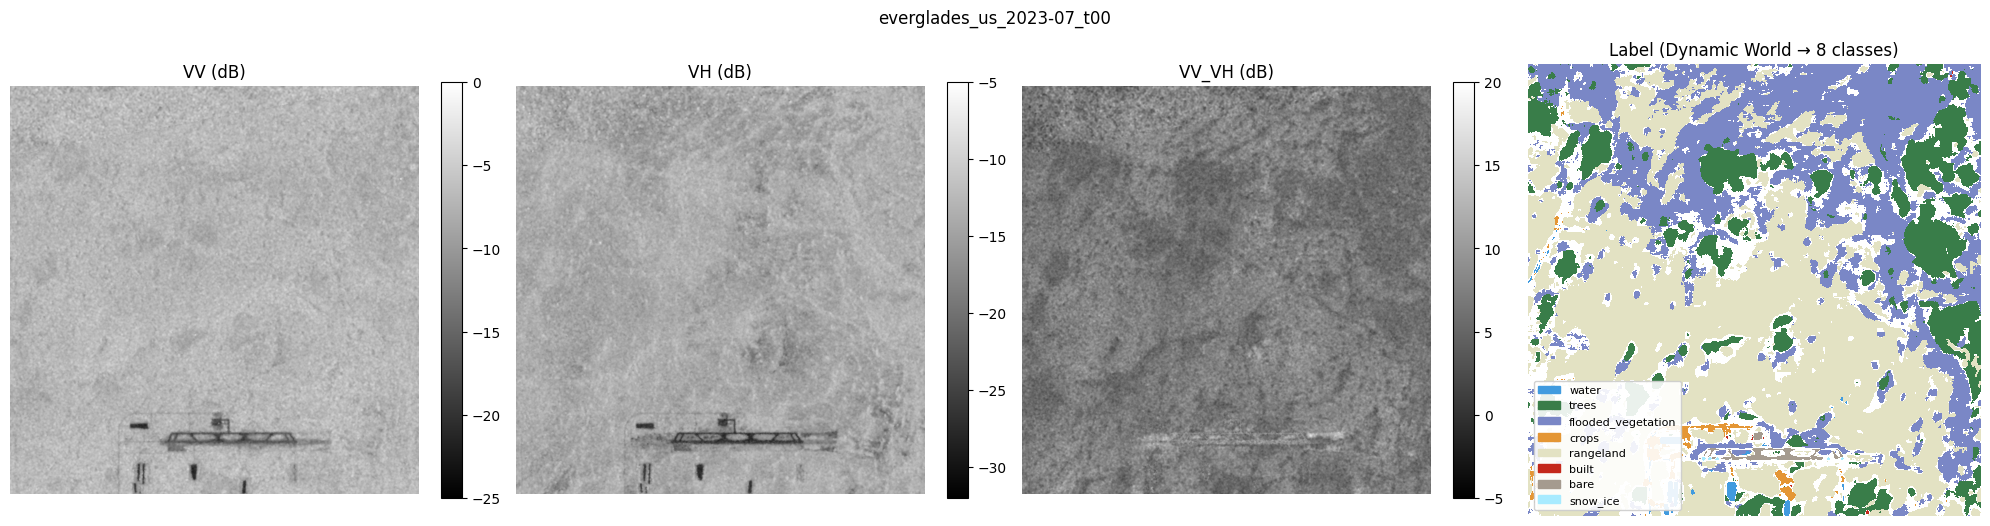

In [7]:
def show_tile(path):
    s1, label = P.load_tile(path)
    fig, ax = plt.subplots(1, 4, figsize=(20, 5.5))
    for i, (band, (lo, hi)) in enumerate(zip(C.S1_BANDS, C.CLIP_DB)):
        im = ax[i].imshow(s1[..., i], cmap="gray", vmin=lo, vmax=hi)
        ax[i].set_title(f"{band} (dB)")
        plt.colorbar(im, ax=ax[i], fraction=0.046)
    ax[3].imshow(np.ma.masked_equal(label, C.IGNORE), cmap=CMAP, vmin=0, vmax=len(C.CLASSES) - 1,
                 interpolation="nearest")
    ax[3].set_title("Label (Dynamic World → 8 classes)")
    ax[3].legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in C.CLASS_COLORS], C.CLASSES,
                 loc="lower left", fontsize=8, framealpha=0.9)
    for a in ax:
        a.axis("off")
    fig.suptitle(path.stem)
    plt.tight_layout()
    plt.show()

show_tile(C.RAW_DIR / "everglades_us" / "everglades_us_2023-07_t00.tif")

## 4. Full export

Every second month, offset per year so all 12 calendar months are represented: 12 months for train/val
(2023–24) and 11 months for test (2025–26), plus 6 months of 2025–26 for the training areas (`test_temporal`).
Area-months without any Sentinel-1 scene or Dynamic World observation are skipped (e.g. persistent cloud).
Watch the EECU usage on the Earth Engine **Configuration** page (Community tier: 150 EECU-hours per month).

In [8]:
jobs = C.export_jobs()
print(len(jobs), "area-months,", len(jobs) * (C.AOI_PX // C.TILE_PX) ** 2, "tiles")

logs = []
with ThreadPoolExecutor(max_workers=4) as pool:
    futures = {pool.submit(G.export_aoi_month, n, a, m): (n, m) for n, a, m in jobs}
    for f in tqdm(as_completed(futures), total=len(futures)):
        try:
            logs.append(f.result())
        except Exception as e:
            n, m = futures[f]
            logs.append(dict(aoi=n, month=m, status=f"error: {e}"))

logs = pd.DataFrame(logs).sort_values(["aoi", "month"])
logs.to_csv(C.DATA_DIR / "export_log.csv", index=False)
logs.status.value_counts()

633 area-months, 2532 tiles


  0%|          | 0/633 [00:00<?, ?it/s]

/home/jovyan/vault/venv-lulc/lib/python3.11/site-packages/ee/data.py:335: UserWarning: Your project has exceeded its noncommercial compute quota and is now in restricted mode. Visit https://developers.google.com/earth-engine/guides/noncommercial_tiers#restricted_mode to learn more.


status
ok                                                                                                                                                                                                            511
error: Too Many Requests: Exceeded Earth Engine concurrency limit. Your project is in Restricted Mode. Learn more at https://developers.google.com/earth-engine/guides/noncommercial_tiers#restricted_mode     82
skipped: no S1 or DW images                                                                                                                                                                                    40
Name: count, dtype: int64

In [9]:
print("Skipped area-months:")
logs[logs.status != "ok"][["aoi", "month", "s1", "dw", "status"]]

Skipped area-months:


,aoi,month,s1,dw,status
118,amazon_br,2023-01,5.0,0.0,skipped: no S1 or DW images
128,amazon_br,2024-12,7.0,0.0,skipped: no S1 or DW images
542,amazon_br,2026-05,NaN,NaN,error: Too Many Requests: Exceeded Earth Engin...
362,anatolia_tr,2023-09,NaN,NaN,error: Too Many Requests: Exceeded Earth Engin...
367,anatolia_tr,2024-10,NaN,NaN,error: Too Many Requests: Exceeded Earth Engin...
...,...,...,...,...,...
458,vatnajokull_is,2025-01,NaN,NaN,error: Too Many Requests: Exceeded Earth Engin...
459,vatnajokull_is,2025-05,NaN,NaN,error: Too Many Requests: Exceeded Earth Engin...
463,vatnajokull_is,2025-11,NaN,NaN,error: Too Many Requests: Exceeded Earth Engin...
468,vatnajokull_is,2026-10,NaN,NaN,error: Too Many Requests: Exceeded Earth Engin...


**Export result.** 511 of 633 area-months were exported. 40 were skipped because there was no Sentinel-1 scene or no
cloud-free Dynamic World observation in that month (e.g. Amazon, Lagos, Paris in cloudy months). 82 failed because the
Earth Engine project had used up its monthly noncommercial quota (Community tier) and was switched to *restricted mode*;
this removed **all months of the Everest training area** and some months of other areas (e.g. Anatolia, Vatnajökull).
The dataset below is therefore built from 26 training areas; snow/ice in training comes only from the Aletsch glacier.

In [10]:
print("Sentinel-1 scenes per monthly composite:")
logs.pivot(index="aoi", columns="month", values="s1")

Sentinel-1 scenes per monthly composite:


month,2023-01,2023-03,2023-05,2023-07,2023-09,2023-11,2024-02,2024-04,2024-06,2024-08,...,2025-09,2025-11,2026-01,2026-02,2026-04,2026-05,2026-06,2026-08,2026-09,2026-10
aoi,,,,,,,,,,,,,,,,,,,,,
aletsch_ch,5.0,5.0,5.0,5.0,6.0,5.0,5.0,5.0,5.0,6.0,...,NaN,10.0,10.0,NaN,NaN,14.0,NaN,NaN,10.0,NaN
amazon_br,5.0,4.0,5.0,4.0,6.0,5.0,7.0,8.0,5.0,9.0,...,NaN,6.0,5.0,NaN,NaN,NaN,NaN,NaN,5.0,NaN
anatolia_tr,7.0,7.0,7.0,9.0,NaN,8.0,7.0,7.0,7.0,9.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
atacama_cl,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.0,NaN,NaN,5.0,6.0,NaN,6.0,5.0,NaN,5.0
black_forest_de,5.0,5.0,5.0,5.0,6.0,5.0,5.0,5.0,5.0,6.0,...,NaN,10.0,10.0,NaN,NaN,14.0,NaN,NaN,10.0,NaN
black_rock_us,6.0,6.0,6.0,5.0,5.0,5.0,5.0,6.0,5.0,5.0,...,NaN,4.0,3.0,NaN,NaN,5.0,NaN,NaN,5.0,NaN
borneo_id,3.0,3.0,2.0,2.0,2.0,2.0,3.0,3.0,1.0,3.0,...,NaN,2.0,2.0,NaN,NaN,2.0,NaN,NaN,3.0,NaN
canterbury_nz,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,5.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chicago_us,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,2.0,...,NaN,2.0,1.0,NaN,NaN,3.0,NaN,NaN,5.0,NaN


In [11]:
print("Dynamic World observations per label month:")
logs.pivot(index="aoi", columns="month", values="dw")

Dynamic World observations per label month:


month,2023-01,2023-03,2023-05,2023-07,2023-09,2023-11,2024-02,2024-04,2024-06,2024-08,...,2025-09,2025-11,2026-01,2026-02,2026-04,2026-05,2026-06,2026-08,2026-09,2026-10
aoi,,,,,,,,,,,,,,,,,,,,,
aletsch_ch,4.0,5.0,3.0,7.0,7.0,2.0,3.0,4.0,2.0,8.0,...,NaN,9.0,3.0,NaN,NaN,8.0,NaN,NaN,15.0,NaN
amazon_br,0.0,2.0,2.0,6.0,5.0,3.0,3.0,1.0,1.0,5.0,...,NaN,1.0,1.0,NaN,NaN,NaN,NaN,NaN,1.0,NaN
anatolia_tr,10.0,3.0,10.0,21.0,NaN,9.0,13.0,11.0,22.0,23.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
atacama_cl,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,16.0,NaN,NaN,19.0,13.0,NaN,14.0,8.0,NaN,10.0
black_forest_de,1.0,2.0,6.0,7.0,11.0,1.0,3.0,1.0,4.0,11.0,...,NaN,2.0,7.0,NaN,NaN,13.0,NaN,NaN,23.0,NaN
black_rock_us,8.0,7.0,9.0,12.0,9.0,8.0,7.0,11.0,12.0,12.0,...,NaN,10.0,9.0,NaN,NaN,11.0,NaN,NaN,9.0,NaN
borneo_id,0.0,0.0,2.0,2.0,2.0,2.0,0.0,1.0,2.0,1.0,...,NaN,1.0,0.0,NaN,NaN,0.0,NaN,NaN,1.0,NaN
canterbury_nz,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,3.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
chicago_us,1.0,1.0,4.0,6.0,2.0,2.0,3.0,2.0,2.0,1.0,...,NaN,2.0,0.0,NaN,NaN,2.0,NaN,NaN,3.0,NaN


## 5. Integrity check

An interrupted download can leave an unreadable file. Such tiles are listed here; delete them with
`python scripts/check_tiles.py --delete` and re-run the export.

In [12]:
bad = P.find_unreadable()
print(len(list(C.RAW_DIR.rglob("*.tif"))), "tiles,", len(bad), "unreadable")
bad

2265 tiles, 0 unreadable


[]

## 6. Patching, splits and class distribution

* Each tile is cut into non-overlapping 256 × 256 patches.
* A patch is dropped if any S1 pixel is missing, or if fewer than 50 % of its pixels have a reliable label.
* Arrays are stored in dB (float16); clipping and normalisation happen in the training pipeline using
  `stats.json`, computed on the **training split only**.

In [13]:
metas = {s: P.build_split(s) for s in C.SPLITS}
pd.DataFrame({s: {"areas": m.aoi.nunique(), "months": m.month.nunique(), "patches": len(m)}
              for s, m in metas.items()}).T

,areas,months,patches
train,26,12,14952
val,4,12,1808
test,9,11,4536
test_temporal,26,6,7041


In [14]:
pd.concat(metas, names=["split"]).reset_index(0).groupby(["aoi", "split"]).size().unstack(fill_value=0)

split,test,test_temporal,train,val
aoi,,,,
aletsch_ch,0,198,302,0
amazon_br,0,102,350,0
anatolia_tr,0,0,0,691
atacama_cl,641,0,0,0
black_forest_de,0,191,398,0
black_rock_us,0,381,762,0
borneo_id,0,73,170,0
canterbury_nz,509,0,0,0
chicago_us,0,298,741,0


,train,val,test,test_temporal
class,,,,
water,9.10,16.05,5.20,9.83
trees,11.49,12.73,13.97,11.82
flooded_vegetation,2.85,2.54,0.08,1.55
crops,20.26,23.86,12.88,20.05
rangeland,12.12,4.36,11.08,12.97
built,23.65,24.70,24.20,23.37
bare,17.97,15.74,19.06,17.51
snow_ice,2.56,0.02,13.54,2.90


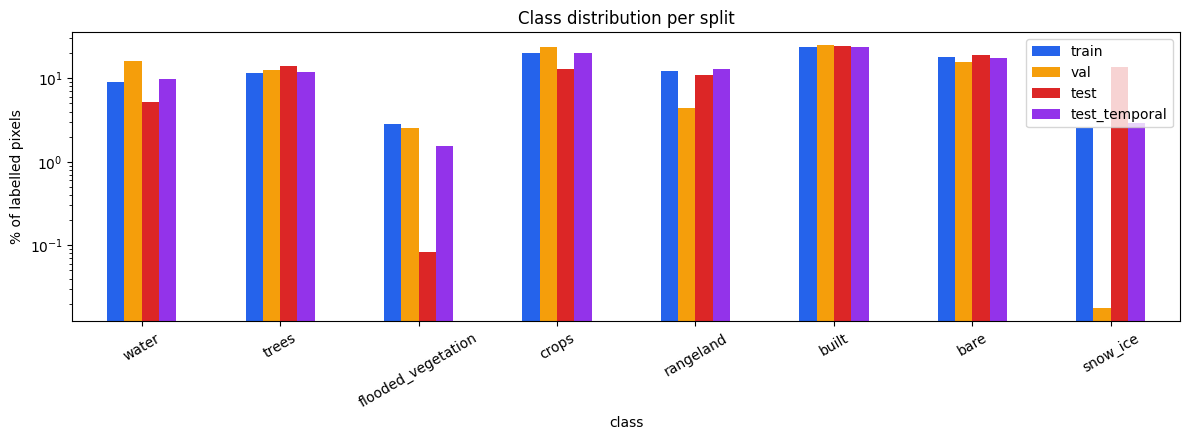

In [15]:
dist = pd.concat({s: P.class_distribution(s).set_index("class")["percent"] for s in metas}, axis=1)
display(dist.round(2))

ax = dist.plot.bar(figsize=(12, 4.5), color=["#2563eb", "#f59e0b", "#dc2626", "#9333ea"], rot=30)
ax.set_ylabel("% of labelled pixels")
ax.set_title("Class distribution per split")
ax.set_yscale("log")
plt.tight_layout()
plt.show()

In [16]:
stats = P.normalisation_stats()
stats

{'bands': ['VV', 'VH', 'VV_VH'],
 'clip': [(-25.0, 0.0), (-32.0, -5.0), (-5.0, 20.0)],
 'mean': [-10.629285028722842, -18.848406296823356, 8.324424649474146],
 'std': [4.770246471147043, 5.945288009546528, 3.3018265430097307]}

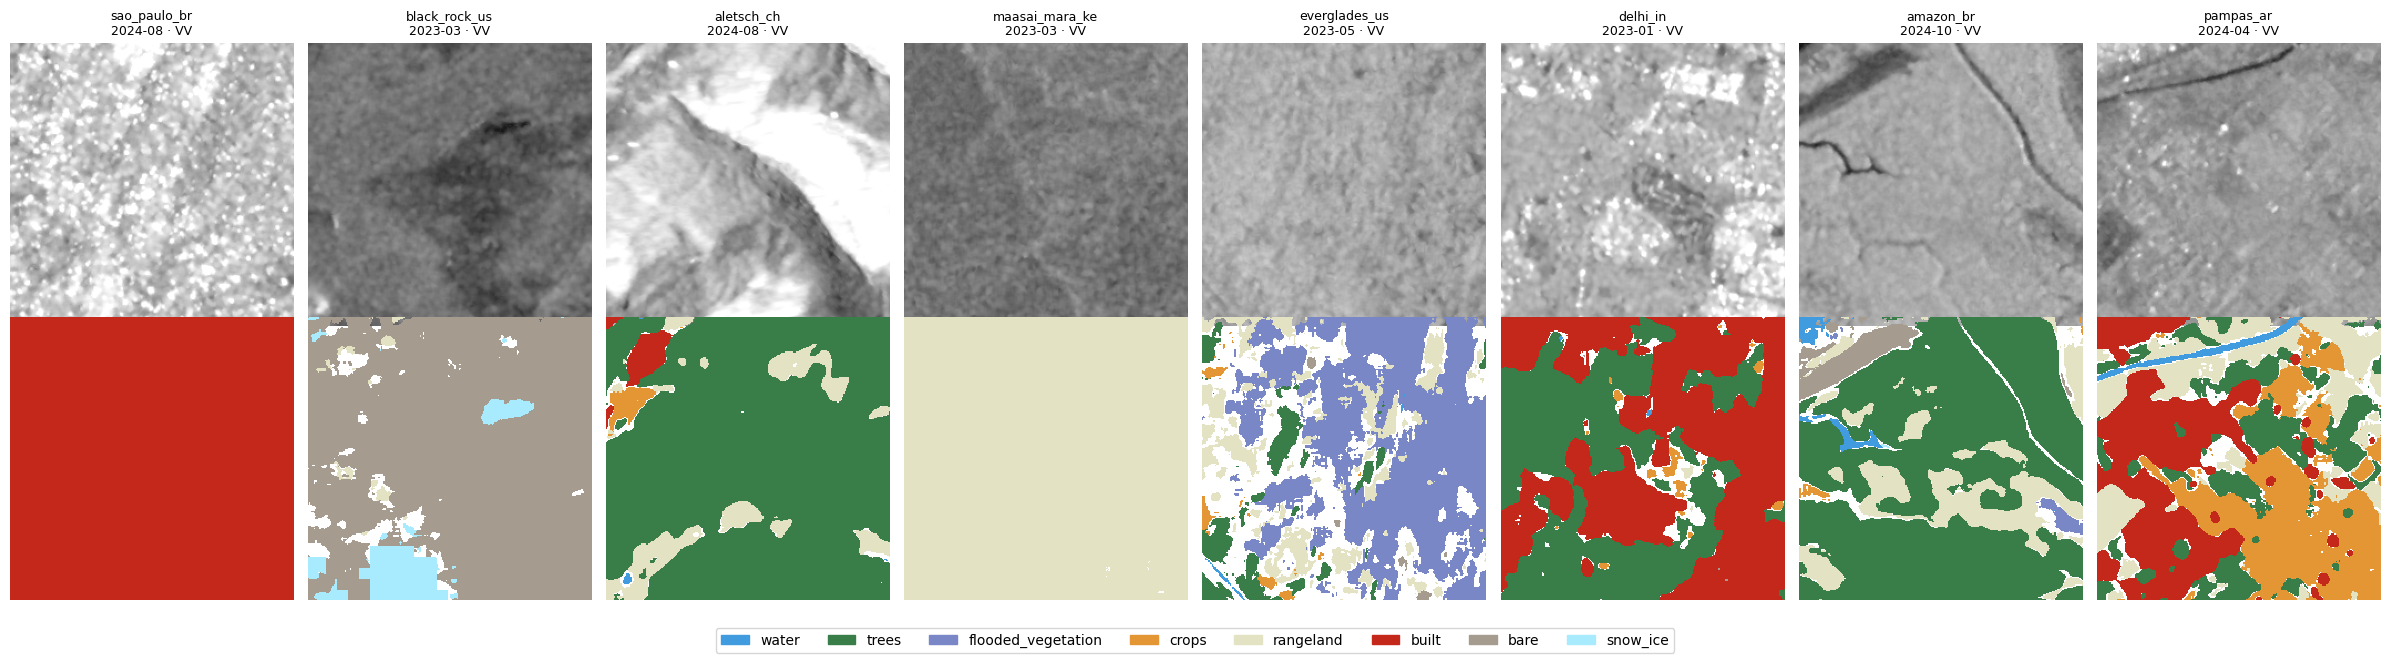

In [17]:
X = np.load(C.PATCH_DIR / "X_train.npy", mmap_mode="r")
y = np.load(C.PATCH_DIR / "y_train.npy", mmap_mode="r")
meta = metas["train"]
idx = np.random.default_rng(0).choice(len(X), 8, replace=False)

fig, ax = plt.subplots(2, 8, figsize=(24, 6.5))
for j, i in enumerate(idx):
    ax[0, j].imshow(X[i, ..., 0].astype(np.float32), cmap="gray", vmin=-25, vmax=0)
    ax[0, j].set_title(f"{meta.aoi[i]}\n{meta.month[i]} · VV", fontsize=9)
    ax[1, j].imshow(np.ma.masked_equal(y[i], C.IGNORE), cmap=CMAP, vmin=0, vmax=len(C.CLASSES) - 1,
                    interpolation="nearest")
for a in ax.ravel():
    a.axis("off")
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in C.CLASS_COLORS], C.CLASSES, loc="lower center",
           ncol=len(C.CLASSES))
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

## Preprocessing summary (for the report)

| Step | Where | Detail |
|---|---|---|
| Thermal noise removal, radiometric calibration (σ⁰), terrain correction (SRTM 30 m), dB conversion | GEE `COPERNICUS/S1_GRD` | Applied by GEE with the ESA SNAP toolbox |
| Scene selection | `s1_collection` | IW mode, VV+VH, 10 m GRD, **one orbit pass per study area** |
| Border noise | `_prep_scene` | VV < −30 dB masked |
| Speckle filtering | `lee_filter` | Lee filter, 5 × 5 window, ENL 4.4, applied in linear power per scene |
| Monthly compositing | `s1_monthly` | Per-pixel median of all filtered scenes in the month (also temporal multi-looking), back to dB; VV−VH ratio band added |
| Label matching | `dw_monthly` | Same month, same 10 m local-UTM grid: mean of Dynamic World class probabilities over cloud-free observations → argmax |
| Class mapping | `patching.load_tile` | 9 Dynamic World classes → 8 classes (grass + shrub/scrub → rangeland) |
| Label quality | `patching.load_tile` | Pixels with mean top-class probability < 0.3 or no DW observation → ignore index 255 |
| Patching | `build_split` | 256 × 256, non-overlapping; patches with S1 gaps or < 50 % labelled pixels dropped |
| Normalisation | `normalisation_stats` | Clip VV [−25, 0], VH [−32, −5], VV−VH [−5, 20] dB, then z-score with training-split mean/std |
| Splits | `config.SPLITS` | By region **and** time: train/val 2023–24, test (unseen regions) 2025–26 |
| Augmentation | notebook 02 | Random flips and 90° rotations; brightness change (same ±1 dB offset on VV and VH); Gaussian speckle-like noise (σ 0.3 dB) |